# Terminal map — global catalog

Starting point for terminal deep-dives. Built from DuckDB trades via:

```bash
python build_terminal_catalog.py
```

**Tables**
- `data/derived/terminals.parquet` — one row per installation
- `data/derived/terminal_products.parquet` — product mix by direction
- `data/derived/terminal_partners.parquet` — top partner countries
- `data/manual/terminal_desk_map.csv` — desk map: owners, `primary_tag`, boolean `tag_*` flags, complexes, pipelines, lat/lon

**Roles:** `export_only` / `import_only` / `hub` (both).

Later layers: regions covered, pipeline connectivity, arb/margins.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..").resolve()
DERIVED = ROOT / "data" / "derived"

terminals = pd.read_parquet(DERIVED / "terminals.parquet")
products = pd.read_parquet(DERIVED / "terminal_products.parquet")
partners = pd.read_parquet(DERIVED / "terminal_partners.parquet")

print(len(terminals), "terminals")
print(terminals["role"].value_counts())
terminals.head()

3071 terminals
role
hub            2009
import_only     775
export_only     287
Name: count, dtype: int64


,terminal_key,installation_id,installation_name,country,zone,zone_id,continent,subcontinent,trading_region,location,...,last_seen,regions_covered,pipeline_connected,pipeline_names,lat,lon,notes,catalog_built_at,status_filter,exclude_crude
0,1266,1266,Jamnagar Refinery,India,Sikka,2358,Asia,South-Central Asia,South-Central Asia,Jamnagar Refinery,...,2026-07-16 05:38:00,None,None,None,None,None,None,2026-07-31T15:40:14.866079+00:00,Delivered,True
1,1350,1350,FOTT,United Arab Emirates,Fujairah,1118,Asia,Middle East,Other Middle East,FOTT,...,2026-07-15 20:19:00,None,None,None,None,None,None,2026-07-31T15:40:14.866079+00:00,Delivered,True
2,1346,1346,Ruwais Refinery,United Arab Emirates,Ruwais,2420,Asia,Middle East,Mideast Gulf,Ruwais Refinery,...,2026-07-01 06:59:00,None,None,None,None,None,None,2026-07-31T15:40:14.866079+00:00,Delivered,True
3,1284,1284,Jubail Industrial Port,Saudi Arabia,Jubail Industrial Port,2374,Asia,Middle East,Mideast Gulf,Jubail Industrial Port,...,2026-07-11 12:38:00,None,None,None,None,None,None,2026-07-31T15:40:14.866079+00:00,Delivered,True
4,1756,1756,JPUT,Singapore Republic,Singapore,1109,Asia,South-East Asia,South-East Asia,JPUT,...,2026-07-15 02:19:00,None,None,None,None,None,None,2026-07-31T15:40:14.866079+00:00,Delivered,True


## Universe snapshot

,n_terminals,total_mb
country,,
United States,327,16352.583264
Singapore Republic,30,10544.197861
Saudi Arabia,27,9503.525437
United Arab Emirates,33,8607.078999
India,48,8425.350898
Russian Federation,62,8060.030026
South Korea,52,7763.466057
Netherlands,79,6687.123412
China,249,5811.827321


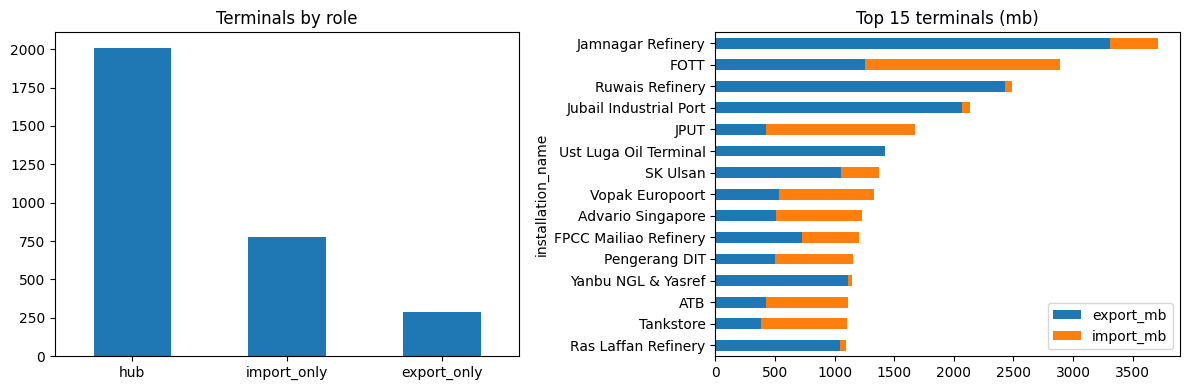

In [2]:
by_country = (
    terminals.groupby("country", dropna=False)
    .agg(n_terminals=("terminal_key", "count"), total_mb=("total_mb", "sum"))
    .sort_values("total_mb", ascending=False)
    .head(20)
)
display(by_country)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
terminals["role"].value_counts().plot(kind="bar", ax=axes[0], title="Terminals by role")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)
(
    terminals.nlargest(15, "total_mb")
    .set_index("installation_name")[["export_mb", "import_mb"]]
    .plot(kind="barh", stacked=True, ax=axes[1], title="Top 15 terminals (mb)")
)
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

## Terminal deep-dive helper

Pick a terminal by name (substring match) or `terminal_key`.

In [3]:
def find_terminals(query: str, n: int = 15) -> pd.DataFrame:
    q = query.lower()
    hit = terminals[
        terminals["installation_name"].fillna("").str.lower().str.contains(q, regex=False)
        | terminals["country"].fillna("").str.lower().str.contains(q, regex=False)
    ]
    return hit.nlargest(n, "total_mb")[
        [
            "terminal_key",
            "installation_name",
            "country",
            "zone",
            "role",
            "export_mb",
            "import_mb",
            "total_mb",
            "looks_like_refinery",
        ]
    ]


def deep_dive(terminal_key: str):
    meta = terminals.loc[terminals["terminal_key"] == terminal_key]
    if meta.empty:
        print("not found:", terminal_key)
        return
    row = meta.iloc[0]
    print("=" * 72)
    print(row["installation_name"], "|", row["country"], "|", row["role"])
    print(
        f"export {row['export_mb']:.1f} mb · import {row['import_mb']:.1f} mb · "
        f"zone={row['zone']} · trading_region={row['trading_region']}"
    )
    print(
        "Enrichment placeholders —",
        f"regions_covered={row['regions_covered']}, "
        f"pipeline_connected={row['pipeline_connected']}, "
        f"pipeline_names={row['pipeline_names']}",
    )
    print("=" * 72)

    prod = products[products["terminal_key"] == terminal_key].copy()
    print("\nProducts")
    display(
        prod.pivot_table(
            index=["family", "product"], columns="direction", values="mb", aggfunc="sum"
        )
        .fillna(0)
        .sort_values(by=list(prod["direction"].unique()), ascending=False)
        .head(25)
    )

    part = partners[partners["terminal_key"] == terminal_key].copy()
    print("\nPartner countries")
    display(part.sort_values("mb", ascending=False).head(30))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, direction, title in [
        (axes[0], "export", "Exports by product (mb)"),
        (axes[1], "import", "Imports by product (mb)"),
    ]:
        sub = prod[prod["direction"] == direction].nlargest(10, "mb")
        if sub.empty:
            ax.set_title(title + " — none")
            ax.axis("off")
            continue
        sub.set_index("product")["mb"].plot(kind="barh", ax=ax, title=title)
        ax.invert_yaxis()
    plt.tight_layout()
    plt.show()
    return {"meta": row, "products": prod, "partners": part}


# Examples
display(find_terminals("Cartagena"))
display(find_terminals("Sines"))
display(find_terminals("Fos"))

,terminal_key,installation_name,country,zone,role,export_mb,import_mb,total_mb,looks_like_refinery
76,1243,Repsol Cartagena Refinery,Spain,Cartagena,hub,372.825098,98.369144,471.194242,True
1380,2567,Oiltank. Cartagena,Colombia,Cartagena (Colombia),hub,0.119915,5.810457,5.930372,False
1865,2568,Vopak Cartagena,Colombia,Cartagena (Colombia),hub,0.763555,0.865649,1.629204,False
2022,3427,Algranel Cartagena,Colombia,Cartagena (Colombia),hub,0.011655,1.041461,1.053116,False
2110,8474,Plexaport Cartagena,Colombia,Cartagena (Colombia),hub,0.603479,0.236530,0.840009,False
2929,12490,Timab Cartagena,Spain,Cartagena,import_only,0.000000,0.042120,0.042120,False


,terminal_key,installation_name,country,zone,role,export_mb,import_mb,total_mb,looks_like_refinery
56,2457,Sines Products,Portugal,Sines,hub,446.783717,123.006127,569.789844,False
1292,1261,Sines Refinery,Portugal,Sines,hub,1.518135,6.281543,7.799678,True


,terminal_key,installation_name,country,zone,role,export_mb,import_mb,total_mb,looks_like_refinery
90,1274,Fos Sur Mer,France,Fos,hub,100.635810,324.657564,425.293374,False
1760,8837,CNPC Foshan Asphalt Terminal,China,Gaoming,hub,0.190928,2.001791,2.192719,False
2216,349,ArcelorMittal Fos Sur Mer,France,Fos,hub,0.633634,0.003742,0.637376,False


Repsol Cartagena Refinery | Spain | hub
export 372.8 mb · import 98.4 mb · zone=Cartagena · trading_region=MED Zone (MED Sea+Black Sea)
Enrichment placeholders — regions_covered=None, pipeline_connected=None, pipeline_names=None

Products


direction                                export     import
family             product                                
Light Ends         Naphtha           144.175300   3.354084
Middle Distillates Gasoil             81.006131  10.813139
                   Diesel             69.911347   4.446994
                   Jet                20.382355   1.821788
Light Ends         Gasoline           20.353504   5.604464
DPP                FO                 12.796724  31.063450
Light Ends         Blending Comps     12.630019   4.808596
DPP                Dirty Feedstocks   10.012553  24.129170
                   Bitumen/Asphalt     0.973475   0.000000
                   Specialities        0.206254   0.000000
                   Slurry              0.200487   0.000000
                   SRFO                0.110014  11.899220
Middle Distillates Kerosene            0.034411   0.026630
DPP                CBFS                0.032524   0.106064
Light Ends         Clean Condensate    0.000000   0.207362
DPP                Coal Tar            0.000000   0.088183


Partner countries


,terminal_key,installation_id,installation_name,direction,partner_country,mb
180,1243,1243,Repsol Cartagena Refinery,export_to,Spain,103.661353
658,1243,1243,Repsol Cartagena Refinery,export_to,France,45.822862
716,1243,1243,Repsol Cartagena Refinery,export_to,Morocco,42.917107
750,1243,1243,Repsol Cartagena Refinery,export_to,Brazil,41.147527
763,1243,1243,Repsol Cartagena Refinery,export_to,Italy,40.397140
997,1243,1243,Repsol Cartagena Refinery,import_from,Spain,33.195308
1532,1243,1243,Repsol Cartagena Refinery,export_to,Netherlands,22.859638
1607,1243,1243,Repsol Cartagena Refinery,import_from,Russian Federation,21.780633
2591,1243,1243,Repsol Cartagena Refinery,export_to,Belgium,13.409249
4093,1243,1243,Repsol Cartagena Refinery,export_to,South Korea,7.728981


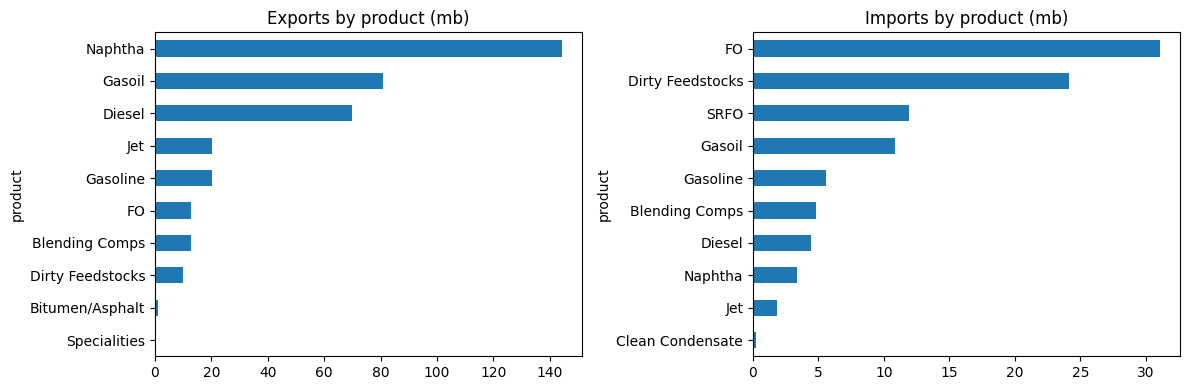

In [4]:
# Pick a terminal_key from find_terminals() and deep-dive
example = find_terminals("Cartagena", n=1)
if len(example):
    deep_dive(example.iloc[0]["terminal_key"])

## Country slice (e.g. Spain / France / Portugal)

In [5]:
FOCUS = ["Spain", "France", "Portugal"]
focus = terminals[terminals["country"].isin(FOCUS)].copy()
print(len(focus), "terminals in", FOCUS)
display(
    focus.nlargest(25, "total_mb")[
        [
            "installation_name",
            "country",
            "role",
            "export_mb",
            "import_mb",
            "total_mb",
            "looks_like_refinery",
        ]
    ]
)

138 terminals in ['Spain', 'France', 'Portugal']


,installation_name,country,role,export_mb,import_mb,total_mb,looks_like_refinery
56,Sines Products,Portugal,hub,446.783717,123.006127,569.789844,False
65,Le Havre,France,hub,92.782110,431.244569,524.026679,False
76,Repsol Cartagena Refinery,Spain,hub,372.825098,98.369144,471.194242,True
90,Fos Sur Mer,France,hub,100.635810,324.657564,425.293374,False
101,La Mede & Fluxys Lavera,France,hub,222.957544,156.936329,379.893873,False
124,Gibraltar-San Roque Refinery,Spain,hub,241.113279,94.866524,335.979803,True
126,Bilbao Oil Facilities,Spain,hub,225.512999,109.649497,335.162496,False
141,Donges Refinery,France,hub,206.189125,92.628330,298.817455,True
148,Tarragona Refinery,Spain,hub,149.822575,138.391799,288.214374,True
150,North Atlantic Port Jerome Refinery,France,hub,214.609702,67.443377,282.053079,True


## Enrichment workflow (next)

1. Edit `data/manual/terminal_desk_map.csv` (filter to your country in Excel) with:
   - `primary_tag` — exclusive bucket (refinery, storage, bunkering, …)
   - `tag_*` — TRUE or blank; a site can have several flags
   - `regions_covered` — hinterland / PADD-like region
   - `pipeline_connected` — True/False/Unknown
   - `pipeline_names` — e.g. CLH, SPSE, …
   - `lat` / `lon` — for maps
   - `notes` — desk context
2. Merge back on `terminal_key`.
3. Later: join arb/margin signals to the same keys.

`zone` / `zone_id` are seeded from Kpler on rebuild. Pipeline connectivity and
hinterland labels need external/reference data layered onto this activity map.